# B4 · Contextual baselines

B3 showed that fixed thresholds can't tell a hairpin from a stricken car. Here "normal" is learned **per track and
per point of the lap**, and a car is flagged when it is far slower than normal *at that point*, for long enough.

**Method** (`pipeline/fw47_core/baseline.py`):
- **v1:** for each track and each 25 m of lap distance, the median speed of clean laps (interpolated between bin
  centres) and a robust spread: 1.4826 × MAD of the residuals, floored at 3 km/h.
- **v2:** v1 scaled by the car's own pace this race: the median of speed / expected − 1 over its previous 5 clean
  laps (only earlier laps; v1 until it has 3).
- **Score:** robust z = (speed − expected) / spread. **Alert:** z < −k for at least d seconds.
- **Distance** is the raw integrated lap distance from B2 (not the normalised one). A live scorer can't know a
  lap's final length until the lap ends.

**No car is scored against its own laps.** `analysis/score_b4.py` builds each car's baseline from the *other* cars'
clean laps in that race (leave-one-car-out). Data: 2024, the only season with car data so far; the 2023 download
is running, which will allow a check across seasons (baseline from 2023, scored on 2024).

```bash
.venv/bin/python analysis/score_b4.py --seasons 2024
```

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)   # numpy timedelta 'generic' unit, from pandas internals

from fw47_core import baseline as bl

SCORED = Path('..') / 'data' / 'scored' / 'b4'
CLEAN = Path('..') / 'data' / 'clean'
RAW = Path('..') / 'data' / 'parquet'
SEASON = 2024
pd.set_option('display.max_columns', 30)

sessions = pd.read_parquet(RAW / 'sessions' / f'season={SEASON}' / 'sessions.parquet').set_index('session_key')
track = sessions['circuit_short_name']
keys = sorted(int(f.stem) for f in (SCORED / f'season={SEASON}').glob('*.parquet'))
laps = pd.concat([pd.read_parquet(CLEAN / 'laps' / f'season={SEASON}' / f'{k}.parquet') for k in keys], ignore_index=True)
clean_hours = laps.loc[laps['clean'], 'lap_duration'].sum() / 3600

COLS = ['driver_number', 'lap_number', 'date', 'speed', 'rpm', 'throttle', 'lap_distance_m', 'exp_kmh', 'exp2_kmh',
        'scale_kmh', 'z', 'z2', 'offset', 'clean', 'missing_duration']
data = {}
for k in keys:
    s = pd.read_parquet(SCORED / f'season={SEASON}' / f'{k}.parquet', columns=COLS)
    blue = bl.blue_flags(pd.read_parquet(RAW / 'race_control' / f'season={SEASON}' / f'{k}.parquet'))
    data[k] = dict(clean=s[s['clean']].sort_values(['driver_number', 'date']).reset_index(drop=True),
                   retired=s[s['missing_duration']].sort_values(['driver_number', 'date']).reset_index(drop=True),
                   all=s, blue=blue)
print(f'{len(keys)} races, {clean_hours:.0f} clean car-hours, {laps.missing_duration.sum()} retirement laps (no lap time)')

24 races, 515 clean car-hours, 72 retirement laps (no lap time)


## 1. The expected-speed band, with a real incident

Melbourne 2024: the band is expected ± 6 spreads (v2, for car 44), with Hamilton's lap 16 over it. His engine
failed (B3: rpm to 0 at 210 km/h).

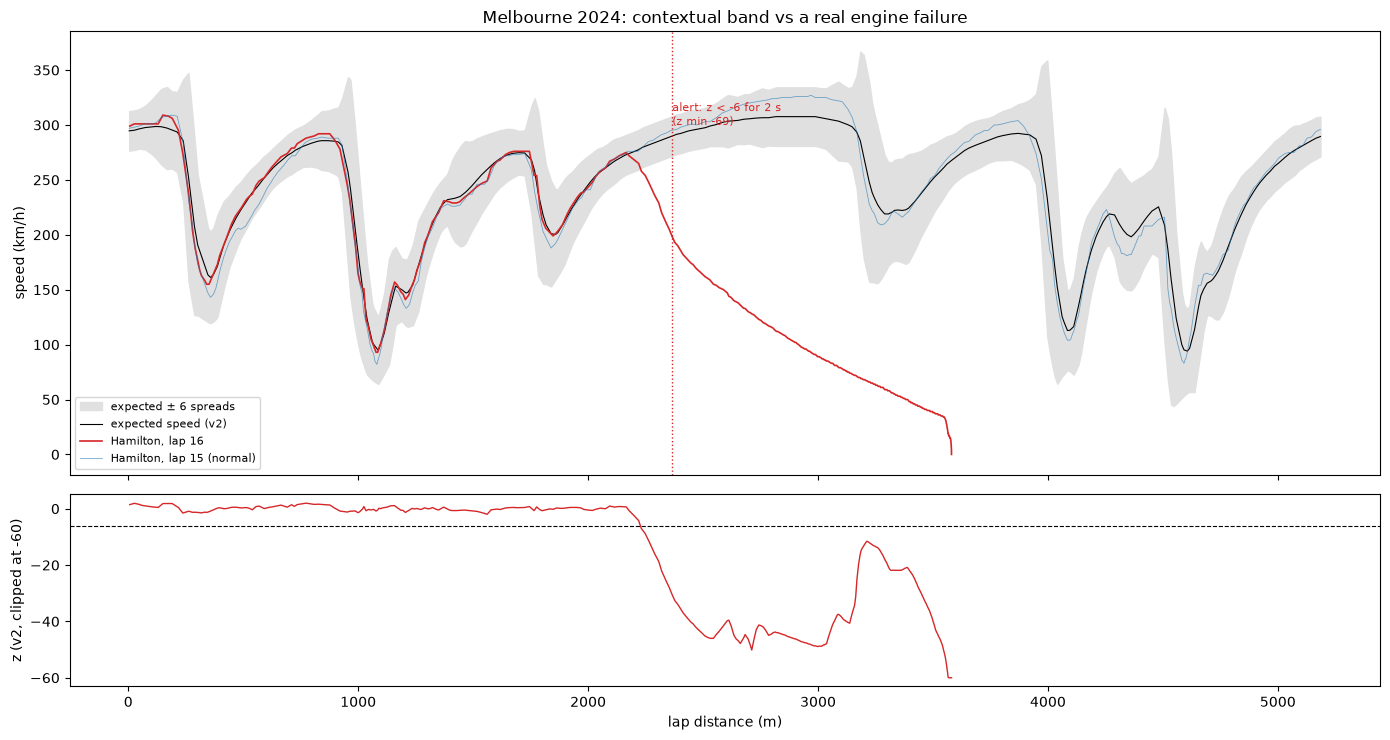

In [2]:
k = int(sessions.index[track.eq('Melbourne')][0])
s = data[k]['all']
lap = s[(s.driver_number == 44) & (s.lap_number == 16)].sort_values('date')
prev = s[(s.driver_number == 44) & (s.lap_number == 15)].sort_values('date')
ep = bl.detect(lap.reset_index(drop=True), bl.DEFAULT_K, bl.DEFAULT_D_S, z_col='z2')

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(14, 7.5), sharex=True, gridspec_kw={'height_ratios': [3, 1.3]})
o = np.argsort(prev.lap_distance_m.to_numpy())
d = prev.lap_distance_m.to_numpy()[o]
e2, sc = prev.exp2_kmh.to_numpy()[o], prev.scale_kmh.to_numpy()[o]
ax.fill_between(d, e2 - bl.DEFAULT_K * sc, e2 + bl.DEFAULT_K * sc, color='0.88', label=f'expected ± {bl.DEFAULT_K:g} spreads')
ax.plot(d, e2, color='k', lw=.8, label='expected speed (v2)')
ax.plot(lap.lap_distance_m, lap.speed, color='tab:red', lw=1.2, label='Hamilton, lap 16')
ax.plot(prev.lap_distance_m, prev.speed, color='tab:blue', lw=.6, alpha=.6, label='Hamilton, lap 15 (normal)')
for e in ep.head(1).itertuples():   # first alert; later ones are the car coasting to a stop
    x = lap.set_index('date').loc[e.alert_at, 'lap_distance_m']
    ax.axvline(x, color='tab:red', ls=':', lw=1)
    ax.annotate(f'alert: z < -{bl.DEFAULT_K:g} for {bl.DEFAULT_D_S:g} s\n(z min {e.z_min:.0f})', (x, 300), fontsize=8, color='tab:red')
ax.set(ylabel='speed (km/h)', title='Melbourne 2024: contextual band vs a real engine failure'); ax.legend(loc='lower left', fontsize=8)
ax2.plot(lap.lap_distance_m, lap.z2.clip(lower=-60), color='tab:red', lw=1)
ax2.axhline(-bl.DEFAULT_K, color='k', ls='--', lw=.8)
ax2.set(ylabel='z (v2, clipped at -60)', xlabel='lap distance (m)')
plt.tight_layout()

In [3]:
rpm0 = lap[lap.rpm == 0].date.min()
for e in ep.head(1).itertuples():
    print(f'slowdown starts {e.start:%H:%M:%S.%f}'[:-3], f'| alert {e.alert_at:%H:%M:%S.%f}'[:-3],
          f'| rpm first 0 at {rpm0:%H:%M:%S.%f}'[:-3], f'| alert - rpm0 = {(e.alert_at - rpm0).total_seconds():+.1f} s',
          f'| lasts {e.duration_s:.0f} s')

slowdown starts 04:25:07.773 | alert 04:25:09.893 | rpm first 0 at 04:25:09.453 | alert - rpm0 = +0.4 s | lasts 95 s


The car starts falling below the band ~1.7 s *before* rpm reaches 0 (the engine was already dying), and the
alert fires 0.4 s after it, once the slowdown has lasted 2 s. The impossible-state rule kept from B3 (`engine-stall`)
fires at the same moment for this failure, because it has an rpm signature. (The later episodes on the same lap are
the car coasting back towards the pits.) The baseline's job is the failures that *don't*: a car losing power, limping, or
stopping without the engine cutting out.

## 2. How tight is the band? v1 against v2

Distribution of z on clean laps (scored leave-one-car-out). A tighter distribution means a smaller k can be used for
the same false-alert rate.

In [4]:
c = pd.concat([d['clean'] for d in data.values()])
spread = pd.DataFrame({v: {'median |z|': c[col].abs().median(), 'share z < -4': (c[col] < -4).mean(),
                           '0.1% quantile': c[col].quantile(.001), '0.01% quantile': c[col].quantile(.0001)}
                       for v, col in [('v1', 'z'), ('v2', 'z2')]}).T
offsets = c.groupby([c.index // 10**9, 'driver_number'])['offset'].median()   # one value per car (roughly)
print(f"car pace offsets in the same race: sd {c.groupby('driver_number')['offset'].median().std():.2%}")
spread.round(4)

car pace offsets in the same race: sd 0.40%


,median |z|,share z < -4,0.1% quantile,0.01% quantile
v1,0.6760,0.0031,-8.4503,-27.9072
v2,0.6246,0.0030,-8.4223,-27.8057


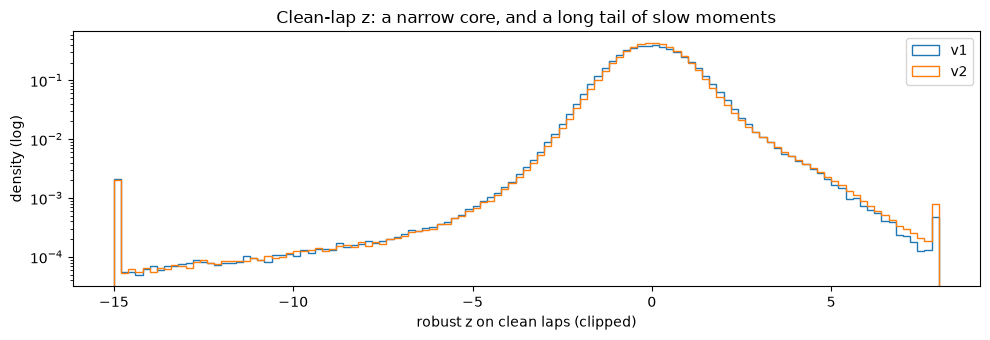

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.5))
bins = np.linspace(-15, 8, 116)
ax.hist(c['z'].clip(-15, 8), bins=bins, histtype='step', label='v1', density=True)
ax.hist(c['z2'].clip(-15, 8), bins=bins, histtype='step', label='v2', density=True)
ax.set_yscale('log'); ax.set(xlabel='robust z on clean laps (clipped)', ylabel='density (log)',
                             title='Clean-lap z: a narrow core, and a long tail of slow moments')
ax.legend(); plt.tight_layout()

v2 is only slightly tighter: once the baseline comes from the *same race*, cars differ by well under 1% in pace.
v2 should matter more when the baseline comes from an earlier season (cars get faster year on year, and the order
changes); that is the cross-season check once 2023 is in. The long left tail is what the persistence condition
has to deal with.

## 3. False alerts per car-hour: k and d

Alert episodes on clean laps per clean car-hour (515), for v1 and v2.

In [6]:
def episodes(kind, k, d, z_col='z2', suppress=False):
    out = []
    for key, dd in data.items():
        s = dd[kind]
        if s.empty: continue
        e = bl.detect(s, k, d, z_col=z_col)
        if suppress and len(e):
            e = e[~bl.after_blue_flag(e.driver_number, e.alert_at, dd['blue'])]
        if len(e):
            out.append(e.assign(session_key=key))
    return pd.concat(out, ignore_index=True)

K, D = [3, 4, 5, 6, 8, 10], [0, 0.5, 1, 2, 3]
grid = pd.DataFrame([(v, k, d, len(episodes('clean', k, d, col)) / clean_hours)
                     for v, col in [('v1', 'z'), ('v2', 'z2')] for k in K for d in D],
                    columns=['baseline', 'k', 'd (s)', 'false alerts / car-hour'])
grid.pivot_table(index=['baseline', 'k'], columns='d (s)', values='false alerts / car-hour').round(2)

d (s)          0.0   0.5   1.0   2.0   3.0
baseline k                                
v1       3   23.91  7.63  4.70  2.52  1.55
         4    8.08  3.13  2.14  1.41  0.96
         5    4.09  1.91  1.48  1.05  0.71
         6    2.58  1.46  1.17  0.85  0.60
         8    1.52  1.03  0.88  0.61  0.43
         10   1.04  0.81  0.68  0.45  0.29
v2       3   21.13  6.98  4.37  2.36  1.48
         4    7.40  2.98  2.05  1.36  0.95
         5    3.83  1.85  1.45  1.03  0.71
         6    2.43  1.43  1.14  0.84  0.60
         8    1.47  1.03  0.87  0.62  0.43
         10   1.06  0.79  0.67  0.46  0.28

Persistence does most of the work at small k: at k = 4, requiring 2 s cuts false alerts by ~5×. Compared with B3
(~314 per car-hour), every setting here is two to three orders of magnitude quieter.

## 4. What is left: who raises the remaining false alerts?

For the provisional setting (k = 6, d = 2 s, v2), each remaining false alert is checked against two kinds of
context: was the car **shown a blue flag** (being lapped: it must let faster cars by) within 30 s, and was it
**within 1 s of the car ahead** (OpenF1 `intervals`)?

In [7]:
fa = episodes('clean', bl.DEFAULT_K, bl.DEFAULT_D_S)
blue_any, close = [], []
for key, g in fa.groupby('session_key'):
    b = data[key]['blue']
    blue_any += [((b.driver_number == d) & ((b.date - t).abs() <= pd.Timedelta(seconds=30))).any()
                 for d, t in zip(g.driver_number, g.start)]
    iv = pd.read_parquet(RAW / 'intervals' / f'season={SEASON}' / f'{key}.parquet')[['date', 'driver_number', 'interval']]
    iv['interval'] = pd.to_numeric(iv['interval'], errors='coerce')
    m = pd.merge_asof(g.sort_values('start'), iv.dropna().sort_values('date').rename(columns={'date': 'start'}),
                      on='start', by='driver_number', direction='backward', tolerance=pd.Timedelta(seconds=10))
    close += list(m.set_index(g.sort_values('start').index).reindex(g.index)['interval'] < 1)
fa['blue_flag_30s'], fa['within_1s_of_car_ahead'] = blue_any, close
ctx = pd.Series({
    'false alerts (k=6, d=2 s)': len(fa),
    'blue flag to that car within ±30 s': fa.blue_flag_30s.mean(),
    'within 1 s of the car ahead': fa.within_1s_of_car_ahead.mean(),
    'either': (fa.blue_flag_30s | fa.within_1s_of_car_ahead).mean(),
})
ctx.to_frame('').T.style.format({c: '{:.0%}' for c in ctx.index[1:]} | {ctx.index[0]: '{:.0f}'})

,"false alerts (k=6, d=2 s)",blue flag to that car within ±30 s,within 1 s of the car ahead,either
,430,73%,14%,80%


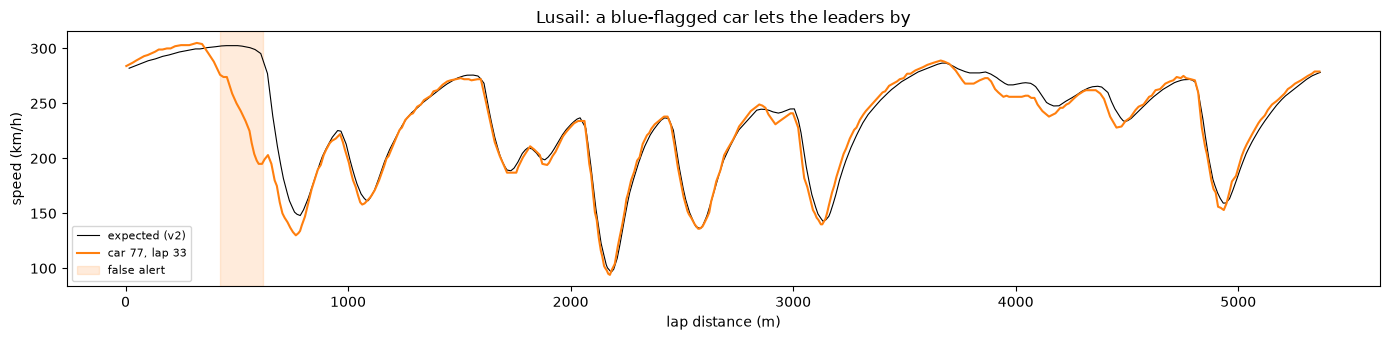

In [8]:
# One example: a lapped car lifting for the leaders
ex = fa[fa.blue_flag_30s].sort_values('z_min').iloc[len(fa[fa.blue_flag_30s]) // 2]
s = data[ex.session_key]['all']
l = s[(s.driver_number == ex.driver_number) & (s.lap_number == ex.lap_number)].sort_values('date')
p = s[(s.driver_number == ex.driver_number) & (s.lap_number == ex.lap_number - 1)].sort_values('date')
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(p.lap_distance_m, p.exp2_kmh, color='k', lw=.8, label='expected (v2)')
ax.plot(l.lap_distance_m, l.speed, color='tab:orange', label=f'car {int(ex.driver_number)}, lap {int(ex.lap_number)}')
x0 = l.set_index('date').loc[ex.start, 'lap_distance_m']
ax.axvspan(x0, x0 + ex.duration_s * l.speed.median() / 3.6, color='tab:orange', alpha=.15, label='false alert')
ax.set(title=f'{track[ex.session_key]}: a blue-flagged car lets the leaders by', xlabel='lap distance (m)', ylabel='speed (km/h)')
ax.legend(fontsize=8); plt.tight_layout()

## 5. Using blue flags as live context

Blue flags come from race control, which is available live, so the scorer can use them. The suppression is
**causal**: an alert is dropped only if the car had *already* been shown a blue flag in the 30 s before the alert
fires. Cost: alerts dropped on the laps where cars retired (a car can be lapped and then fail).

In [9]:
rows = []
for k in [4, 5, 6, 8]:
    for d in [1, 2, 3]:
        fa_all = len(episodes('clean', k, d)); fa_sup = len(episodes('clean', k, d, suppress=True))
        r_all = episodes('retired', k, d).drop_duplicates(['session_key', 'driver_number', 'lap_number'])
        r_sup = episodes('retired', k, d, suppress=True).drop_duplicates(['session_key', 'driver_number', 'lap_number'])
        rows.append((k, d, fa_all / clean_hours, fa_sup / clean_hours, len(r_all), len(r_sup)))
supp = pd.DataFrame(rows, columns=['k', 'd (s)', 'false alerts / car-hour', 'with blue-flag suppression',
                                   'retirement laps alerted', 'retirement laps alerted (suppressed)'])
cover = np.mean([bl.after_blue_flag(dd['clean'].driver_number.iloc[::20], dd['clean'].date.iloc[::20], dd['blue']).mean()
                 for dd in data.values() if len(dd['clean'])])
print(f'share of clean racing time within 30 s after a blue flag: {cover:.1%}')
supp.round(2)

share of clean racing time within 30 s after a blue flag: 0.8%


,k,d (s),false alerts / car-hour,with blue-flag suppression,retirement laps alerted,retirement laps alerted (suppressed)
0,4,1,2.05,1.28,68,67
1,4,2,1.36,0.67,68,66
2,4,3,0.95,0.41,68,66
3,5,1,1.45,0.73,68,66
4,5,2,1.03,0.40,68,66
5,5,3,0.71,0.24,68,66
6,6,1,1.14,0.46,68,66
7,6,2,0.84,0.27,68,66
8,6,3,0.60,0.19,68,66
9,8,1,0.87,0.29,68,66


Blue-flag windows cover under 1% of racing time but remove about two-thirds of the remaining false alerts. At the
provisional setting the detector raises **~0.27 false alerts per car-hour** (about 0.4 per car per race), and still
fires on 66 of the 72 laps where a car retired. Those laps include crashes and are not yet labelled, so this is a
sanity check, not recall: recall and time-to-signal need the B5 labels and are measured in B6.

## 6. Against the B3 rules

In [10]:
b3 = {'emergency-braking': 161.25, 'potential-issue': 149.55, 'power-unit': 1.88, 'drs-failure': 1.45,
      'engine-stall': 0.0, 'gearbox-failure': 0.0}
r = supp.set_index(['k', 'd (s)'])
cmp = pd.DataFrame({'false alerts / car-hour': {
    'B3: all shipped rules': sum(b3.values()),
    'B3: kept impossible-state rules (engine-stall, gearbox, DRS 3+ samples)': 0.03,
    'B4: v2, k=4, d=1 s': r.loc[(4, 1), 'false alerts / car-hour'],
    'B4: v2, k=6, d=2 s': r.loc[(6, 2), 'false alerts / car-hour'],
    'B4: v2, k=6, d=2 s, blue-flag suppression (provisional)': r.loc[(6, 2), 'with blue-flag suppression'],
}})
cmp['per race, 20 cars (~1.5 h)'] = cmp['false alerts / car-hour'] * 1.5 * 20
cmp.round(2)

,false alerts / car-hour,"per race, 20 cars (~1.5 h)"
B3: all shipped rules,314.13,9423.90
"B3: kept impossible-state rules (engine-stall, gearbox, DRS 3+ samples)",0.03,0.90
"B4: v2, k=4, d=1 s",2.05,61.51
"B4: v2, k=6, d=2 s",0.84,25.07
"B4: v2, k=6, d=2 s, blue-flag suppression (provisional)",0.27,8.10


## 7. Severity

Every alert gets a score and a Jira priority (`bl.severity`). The formula, written down before tuning:

$$D = \min\left(1, \frac{-z_{\min}}{20}\right), \quad T = \min\left(1, \frac{\text{duration}}{10\,\text{s}}\right), \quad
\text{score} = 100 \cdot \frac{D + T}{2}$$

Priority: score ≥ 75 Critical, ≥ 50 High, ≥ 25 Medium, else Low. The impossible-state rules kept from B3
(`engine-stall`, `gearbox-failure`, DRS stuck open) are facts rather than degrees, so they are always Critical.
Depth and duration get equal weight: a short, very deep drop (a spin) and a long, moderate one (a car limping back)
should both rank high.

In [11]:
def scored(e):
    sc, pr = bl.severity(e.z_min, e.duration_s)
    return e.assign(score=sc, priority=pr)

fa_s = scored(episodes('clean', bl.DEFAULT_K, bl.DEFAULT_D_S, suppress=True))
ret_s = scored(episodes('retired', bl.DEFAULT_K, bl.DEFAULT_D_S, suppress=True))
ret_s = ret_s.sort_values('score').drop_duplicates(['session_key', 'driver_number', 'lap_number'], keep='last')
order = ['Critical', 'High', 'Medium', 'Low']
pd.DataFrame({'false alerts on clean laps': fa_s.priority.value_counts(normalize=True),
              'strongest alert on each retirement lap': ret_s.priority.value_counts(normalize=True)}
             ).reindex(order).fillna(0).mul(100).round(0)

,false alerts on clean laps,strongest alert on each retirement lap
priority,,
Critical,17.0,98.0
High,46.0,2.0
Medium,37.0,0.0
Low,0.0,0.0


The formula ranks real stoppages above false alerts (98% of retirement laps reach Critical, against 17% of false
alerts), but the bands are too generous: most false alerts still come out High, because anything that survives a
2 s, z < −6 filter is already fairly deep. B6 should set the bands from the labelled data, e.g. reserve Critical
(page someone) for score ≥ 90 and treat the rest as a dashboard item.

## 8. Tracks in the 2025 test season

In [12]:
seasons = {y: set(pd.read_parquet(RAW / 'sessions' / f'season={y}' / 'sessions.parquet')['circuit_short_name']) for y in (2023, 2024, 2025)}
print('2025 circuits without a 2023-2024 baseline:', sorted(seasons[2025] - seasons[2023] - seasons[2024]) or 'none')
print('only in 2024 (no 2023 baseline):', sorted(seasons[2024] - seasons[2023]))

2025 circuits without a 2023-2024 baseline: none
only in 2024 (no 2023 baseline): ['Imola', 'Shanghai']


Every 2025 circuit has a baseline. A re-profiled layout would show up as a different lap length, so the check
before the B6 test is to compare each 2025 race's median clean-lap length with the baseline's (B2 measured ~9 m
lap-to-lap spread, so a change of more than ~1% means a layout change). That only uses lap lengths, not results.

## 9. Export for the scorer

`analysis/export_baselines.py` writes the v1 baseline per circuit (25 m bins) and the detector settings to
`pipeline/baselines/speed_v1.csv` and `speed_v1.json` (~230 KB), so the scorer (A4) can load them without `data/`.

In [13]:
exp = pd.read_csv(Path('..') / 'pipeline' / 'baselines' / 'speed_v1.csv')
import json
meta = json.loads((Path('..') / 'pipeline' / 'baselines' / 'speed_v1.json').read_text())
print(json.dumps({k: meta[k] for k in ('version', 'seasons', 'circuits', 'bin_m', 'detector')}, indent=1))
exp.groupby('circuit_short_name').agg(bins=('bin', 'size'), median_laps_per_bin=('n_laps', 'median'),
                                      median_spread_kmh=('scale_kmh', 'median')).head(8)

{
 "version": "speed_v1",
 "seasons": [
  2023,
  2024
 ],
 "circuits": 24,
 "bin_m": 25,
 "detector": {
  "k": 6.0,
  "d_s": 2.0,
  "sample_gap_s": 1.0,
  "blue_flag_window_s": 30.0,
  "status": "provisional until B6"
 }
}


,bins,median_laps_per_bin,median_spread_kmh
circuit_short_name,,,
Austin,219,1703.0,7.04
Baku,239,1550.0,5.93
Catalunya,187,2282.0,5.85
Hungaroring,175,2318.0,5.75
Imola,196,1119.0,4.45
Interlagos,172,952.0,5.05
Jeddah,245,1514.0,5.93
Las Vegas,248,1371.0,5.93


## 10. Across seasons: a 2023 baseline scoring 2024

Everything above used a baseline from the *same race* (other cars). Live, the scorer only has earlier seasons. Here
each 2024 race is scored against a v1 baseline built from the 2023 race at the same circuit, which is how the B6
test will work (2023–2024 baselines scoring 2025):

```bash
.venv/bin/python analysis/score_b4.py --seasons 2024 --baseline-seasons 2023
```

Imola and Shanghai weren't raced in 2023, and Interlagos 2024 has no clean laps, so those three are left out of
both columns below.

In [14]:
XS = Path('..') / 'data' / 'scored' / 'b4_from_2023' / f'season={SEASON}'
xs_keys = sorted(int(f.stem) for f in XS.glob('*.parquet'))
same = [k for k in xs_keys if len(data[k]['clean'])]
xs = {}
for k in same:
    s = pd.read_parquet(XS / f'{k}.parquet', columns=COLS)
    xs[k] = dict(clean=s[s['clean']].sort_values(['driver_number', 'date']).reset_index(drop=True),
                 retired=s[s['missing_duration']].sort_values(['driver_number', 'date']).reset_index(drop=True),
                 blue=data[k]['blue'])
hours_same = laps[laps.session_key.isin(same) & laps.clean].lap_duration.sum() / 3600

def ep_from(src, kind, k, d, z_col, suppress):
    out = []
    for key, dd in src.items():
        if key not in same or dd[kind].empty: continue
        e = bl.detect(dd[kind], k, d, z_col=z_col)
        if suppress and len(e):
            e = e[~bl.after_blue_flag(e.driver_number, e.alert_at, dd['blue'])]
        if len(e): out.append(e.assign(session_key=key))
    return pd.concat(out, ignore_index=True) if out else pd.DataFrame(columns=['session_key', 'driver_number', 'lap_number'])

rows = []
for name, src in [('same race (leave-one-car-out)', data), ('2023 baseline', xs)]:
    c_ = pd.concat([src[k]['clean'] for k in same])
    for v, col in [('v1', 'z'), ('v2', 'z2')]:
        fa = len(ep_from(src, 'clean', bl.DEFAULT_K, bl.DEFAULT_D_S, col, False)) / hours_same
        fa_s = len(ep_from(src, 'clean', bl.DEFAULT_K, bl.DEFAULT_D_S, col, True)) / hours_same
        ret = ep_from(src, 'retired', bl.DEFAULT_K, bl.DEFAULT_D_S, col, True).drop_duplicates(['session_key', 'driver_number', 'lap_number'])
        rows.append((name, v, c_[col].median(), c_[col].abs().median(), fa, fa_s, len(ret)))
xcmp = pd.DataFrame(rows, columns=['baseline from', 'version', 'median z (bias)', 'median |z|',
                                   'false alerts / car-hour', 'with blue-flag suppression', 'retirement laps alerted (suppressed)'])
print(f'{len(same)} races, {hours_same:.0f} clean car-hours; k={bl.DEFAULT_K:g}, d={bl.DEFAULT_D_S:g} s')
xcmp.round(3)

21 races, 467 clean car-hours; k=6, d=2 s


,baseline from,version,median z (bias),median |z|,false alerts / car-hour,with blue-flag suppression,retirement laps alerted (suppressed)
0,same race (leave-one-car-out),v1,-0.008,0.676,0.819,0.274,62
1,same race (leave-one-car-out),v2,0.024,0.624,0.800,0.263,62
2,2023 baseline,v1,0.348,0.899,0.939,0.374,62
3,2023 baseline,v2,0.033,0.785,0.943,0.372,62


median across circuits: +0.82%, range -0.91% to +2.12%


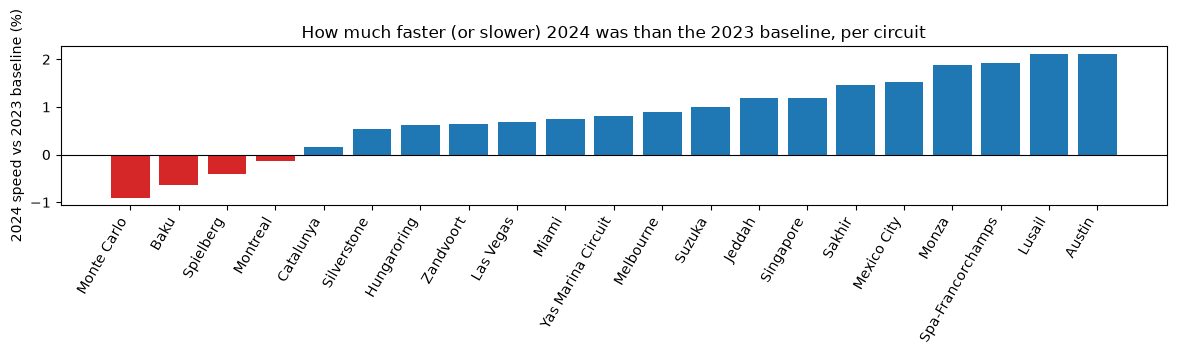

In [15]:
# Year-on-year pace change per circuit: median relative residual of 2024 clean laps against the 2023 baseline
bias = pd.Series({track[k]: (xs[k]['clean'].speed / xs[k]['clean'].exp_kmh - 1).median() * 100 for k in same}).sort_values()
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(bias.index, bias.values, color=['tab:red' if v < 0 else 'tab:blue' for v in bias.values])
ax.axhline(0, color='k', lw=.8)
ax.set(ylabel='2024 speed vs 2023 baseline (%)', title='How much faster (or slower) 2024 was than the 2023 baseline, per circuit')
plt.xticks(rotation=60, ha='right'); plt.tight_layout()
print(f'median across circuits: {bias.median():+.2f}%, range {bias.min():+.2f}% to {bias.max():+.2f}%')

## 11. Findings

**With blue-flag suppression, the contextual detector is over 1,000× quieter than the shipped rules.** On 515 car-hours of clean 2024 racing, scored
leave-one-car-out, the B3 rules raise ~314 false alerts per car-hour. The B4 detector (v2, z < −6 for 2 s) raises
**0.84**, and **0.27 with blue-flag suppression**: about 8 per race across the whole field instead of ~9,400.

**It still catches cars in trouble.** It fires on 66 of the 72 laps on which a car retired (crashes included, and
not yet labelled, so this is a sanity check rather than recall). On Hamilton's Melbourne engine failure the speed
drops out of the band ~1.7 s before rpm reaches 0, and the alert fires 0.4 s after it.

**Persistence matters more than the threshold at low k.** At k = 4, requiring 2 s instead of a single sample cuts
false alerts ~5× (7.4 → 1.4 per car-hour, v2). The clean-lap z distribution has a narrow core (median |z| ≈ 0.6) and a
long tail (0.01% below −28) of short slow moments.

**Most remaining false alerts are lapped cars.** At k = 6, d = 2 s, 73% of them start within 30 s of a blue flag to that
car, and 14% within 1 s of the car ahead (80% one or the other). Blue flags are live race-control data, so the scorer
can use them: suppressing alerts that fire within 30 s *after* a blue flag covers <1% of racing time, removes
two-thirds of false alerts, and drops 2 of the 68 alerted retirement laps.

**Last year's baseline works almost as well as the same race's.** Scoring 2024 against a v1 baseline built only from
the 2023 race at the same circuit (21 races, 467 clean car-hours) is what the live scorer and the B6 test will do.
False alerts rise from 0.26 to 0.37 per car-hour with suppression (0.80 → 0.94 without), and 62 of 64 retirement
laps are still alerted either way (64 of 64 before suppression). Two races account for most of the rise: Montreal (10 → 40 false alerts; only 20% of 2024
laps were clean, all of them on a drying track, against a dry 2023) and Monaco (23 → 46; 2024 was a slow procession
after a lap-1 red flag, ~0.9% under a 2023 baseline). Elsewhere the two are within a few alerts of each other.

**v2 fixes the year-on-year bias but not the false alerts.** Cars got faster: the median 2024 clean lap ran 0.8%
above its 2023 baseline (−0.9% at Monaco to +2.1% at Austin and Lusail), which shifts v1's median z to +0.35. The
per-car offset removes that (median z +0.03, median |z| 0.90 → 0.79), but false alerts don't move (0.37 both): they
are lifts of 6+ spreads, not 1% pace differences. Within a race cars differ by only ~0.4%, so there v2 barely helps
either (median |z| 0.68 → 0.62). It stays in because it costs nothing and keeps z centred; it is not where the false
alerts will be won.

**Severity ranks well, but the bands are too generous.** 98% of retirement laps reach Critical against 17% of false
alerts, but most false alerts still come out High. B6 should set the bands from labelled data.

**2025 has no new tracks**, so every test race has a baseline. Imola and Shanghai have no 2023 baseline (not raced
in 2023). The re-profiling check (median clean-lap length against the baseline, >1% = layout change) runs before
the B6 test.

**Provisional settings** (`baseline.py`, exported with the baselines to `pipeline/baselines/speed_v1.*`):
v2, k = 6, d = 2 s, blue-flag window 30 s. These were chosen on false alerts alone; B6 tunes them on 2023–2024 with
the B5 labels, against time-to-signal.